<a href="https://colab.research.google.com/github/Oli-via123/AI-ML-Practice-and-Projects/blob/main/AI%20and%20ML%20Practice/Customer_Segmentation/Customer_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Customer Segmentation

### Import Libraries

In [ ]:
# Import necessary library
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.ensemble import IsolationForest

### Load and Inspect the Data

In [ ]:
# Load dataset
df = pd.read_csv(r"C:\Users\HP\Desktop\Clustering\Mall_Customers.csv")

# Preview data
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
# Shape of dataset
df.shape

(200, 5)

In [ ]:
# Column names and types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
# Summary statistics
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [ ]:
# Check missing value
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

### Visulization to Understand Distributions

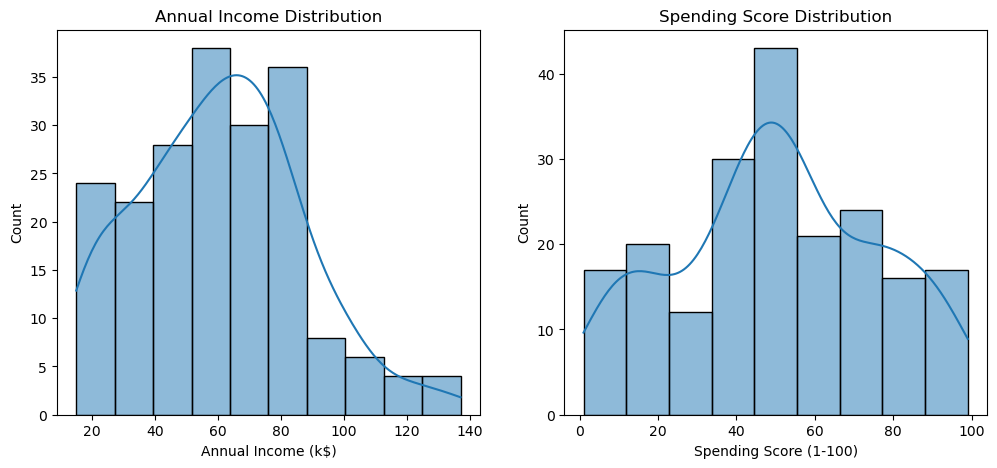

In [ ]:
# Visualize
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.histplot(df['Annual Income (k$)'], kde=True)
plt.title("Annual Income Distribution")

plt.subplot(1,2,2)
sns.histplot(df['Spending Score (1-100)'], kde=True)
plt.title("Spending Score Distribution")

plt.show()

### Feature Selection and Scaling

In [ ]:
# Select feature
x = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# View selected feature
x.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [ ]:
# select the scaling method
scaler = StandardScaler()

# Apply standard scaling
x_scaled = scaler.fit_transform(x)

# View first-five of the scaled data
x_scaled[:5]

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992]])

### Determine Optimum Number of Cluster

In [ ]:
# Find optimal k
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=234)
    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_)

In [ ]:
# View wcss
wcss

[399.99999999999994,
 270.70426664306717,
 195.2466301907915,
 108.92131661364358,
 65.56840815571681,
 55.057348270385965,
 46.80995783413118,
 42.871289711022854,
 32.406659676456606,
 30.028327639008264]

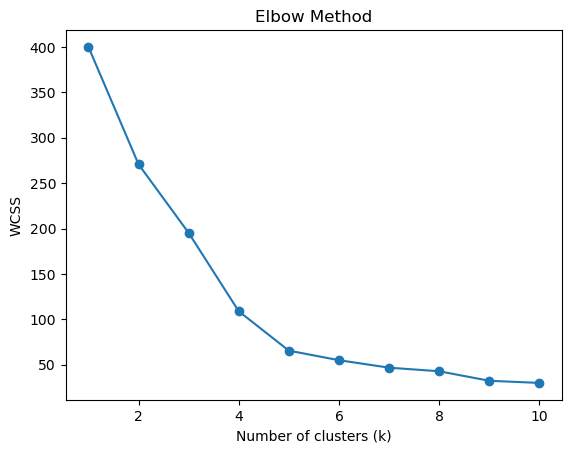

In [ ]:
# Plot elbow curve
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()


### Train K-Means Model

In [ ]:
# Train model
kmeans = KMeans(n_clusters=5, random_state=42)
clusters = kmeans.fit_predict(x_scaled)


In [ ]:
df['Cluster'] = clusters

In [ ]:
# view df
df.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


### Visualize the Clusters

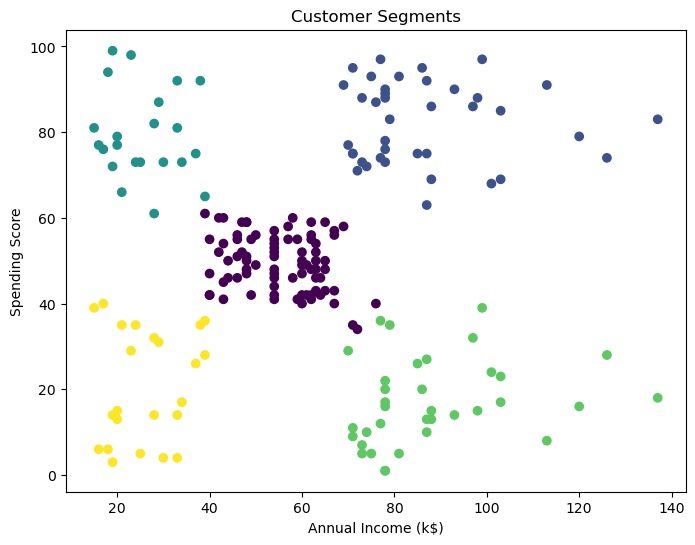

In [ ]:
# Visualize the cluster
plt.figure(figsize=(8,6))
plt.scatter(df['Annual Income (k$)'],
            df['Spending Score (1-100)'],
            c=df['Cluster'])

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')
plt.title('Customer Segments')
plt.show()


### Profile Numerical Cluster

In [ ]:
# Add cluster mean
df.groupby('Cluster')[['Annual Income (k$)', 'Spending Score (1-100)']].mean()

,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.296296,49.518519
1,86.538462,82.128205
2,25.727273,79.363636
3,88.200000,17.114286
4,26.304348,20.913043


In [ ]:
# Cluster size
df['Cluster'].value_counts()

Cluster
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64

### Model Evaluation

In [ ]:
# Evaluate using silhouette
score = silhouette_score(x_scaled, df['Cluster'])
score

0.5546571631111091

## Create a Dendrogram for Hierarchical method

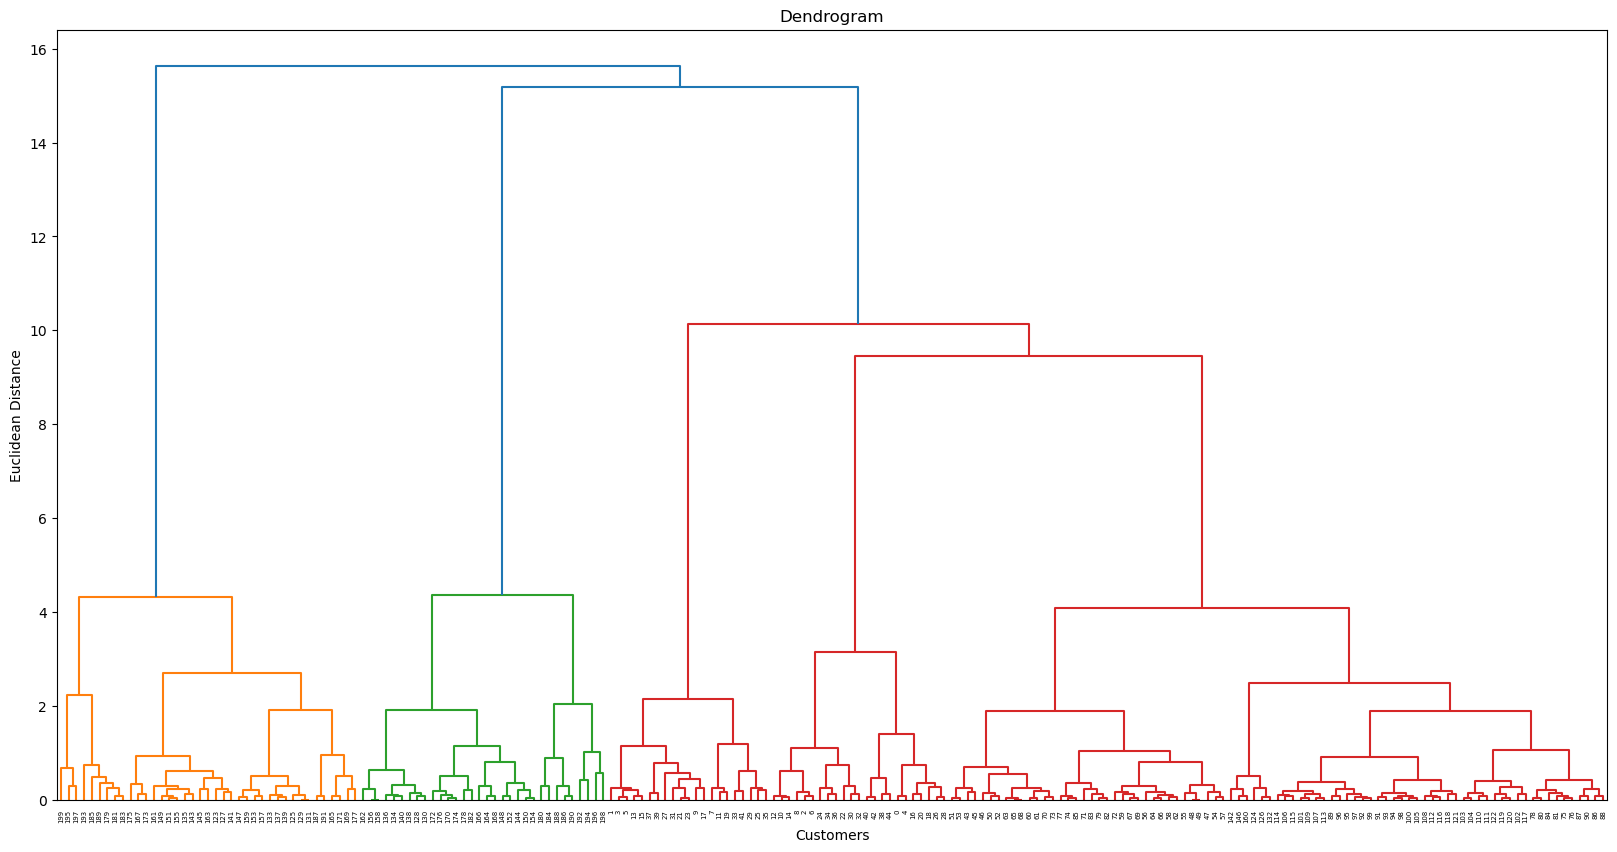

In [ ]:
# Plot the dendrogrm to get number of clusters
plt.figure(figsize=(20,10))

dendrogram(
    linkage(x_scaled, method='ward')
)

plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean Distance')
plt.show()

## Train the Hierarchical Clustering Model

In [ ]:
hc = AgglomerativeClustering(
    n_clusters=4,
    metric='euclidean',
    linkage='ward'
)

hierarchical_clusters = hc.fit_predict(x_scaled)

## Add Cluster Labels to Dataset

In [ ]:
df['Hierarchical_Cluster'] = hierarchical_clusters

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Hierarchical_Cluster
0,1,Male,19,15,39,4,0
1,2,Male,21,15,81,2,3
2,3,Female,20,16,6,4,0
3,4,Female,23,16,77,2,3
4,5,Female,31,17,40,4,0


## Visualize Hierarchical Clusters

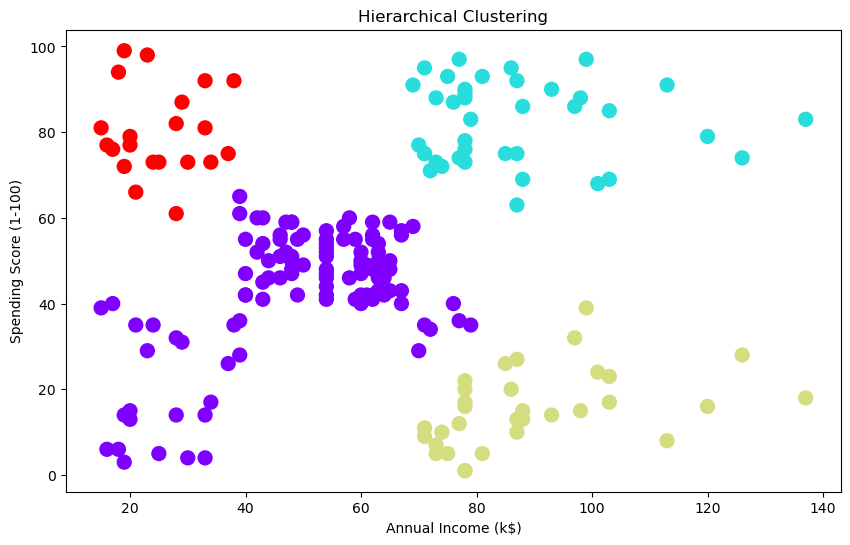

In [ ]:
plt.figure(figsize=(10,6))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Hierarchical_Cluster'],
    cmap='rainbow',
    s=100
)

plt.title('Hierarchical Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

## Evaluate Using Silhouette Score

In [ ]:
hierarchical_silhouette = silhouette_score(
    x_scaled,
    hierarchical_clusters
)

print("Silhouette Score:", hierarchical_silhouette)

Silhouette Score: 0.4925507715349343


In [ ]:
df.groupby('Hierarchical_Cluster')[[
    'Annual Income (k$)',
    'Spending Score (1-100)'
]].mean()

,Annual Income (k$),Spending Score (1-100)
Hierarchical_Cluster,,
0,49.527778,43.120370
1,86.538462,82.128205
2,89.406250,15.593750
3,25.095238,80.047619


## Anomaly Detection

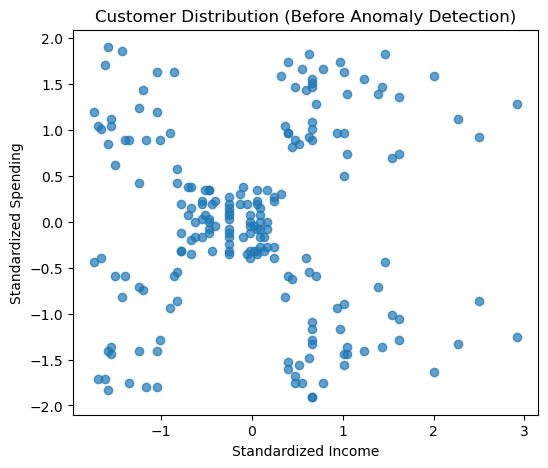

In [ ]:
# Visualize before anomaly
plt.figure(figsize=(6, 5))
plt.scatter(
    x_scaled[:, 0],
    x_scaled[:, 1],
    alpha=0.7
)
plt.xlabel("Standardized Income")
plt.ylabel("Standardized Spending")
plt.title("Customer Distribution (Before Anomaly Detection)")
plt.show()


### Isolation Forest

In [ ]:
# Define the model
iso = IsolationForest(
    n_estimators=100,      # number of trees, more trees = more stable
    contamination=0.05,    # assume ~5% anomalies, adjust later
    random_state=42
)

# Fit the model
iso.fit(x_scaled)

# Predict anomalies
y_iso = iso.predict(x_scaled)

# Add to dataframe
df['anomaly_iso'] = y_iso


In [ ]:
# view df
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Hierarchical_Cluster,anomaly_iso
0,1,Male,19,15,39,4,0,1
1,2,Male,21,15,81,2,3,1
2,3,Female,20,16,6,4,0,1
3,4,Female,23,16,77,2,3,1
4,5,Female,31,17,40,4,0,1


In [ ]:
# anomaly count
df['anomaly_iso'].value_counts()

anomaly_iso
 1    190
-1     10
Name: count, dtype: int64

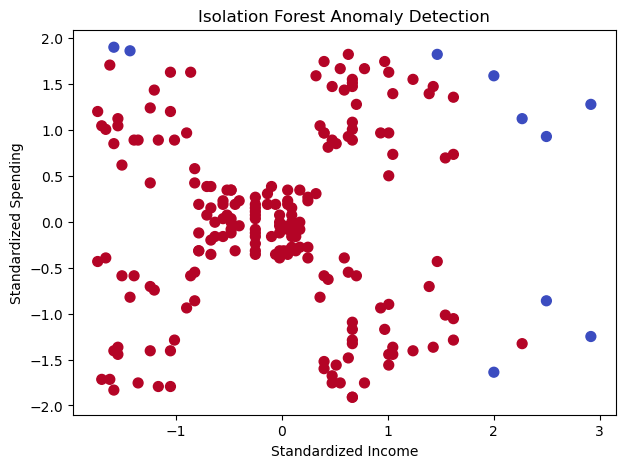

In [ ]:
# visualize anomaly
plt.figure(figsize=(7,5))
plt.scatter(
    x_scaled[:,0],
    x_scaled[:,1],
    c=df['anomaly_iso'],
    cmap='coolwarm',
    s=50
)
plt.xlabel("Standardized Income")
plt.ylabel("Standardized Spending")
plt.title("Isolation Forest Anomaly Detection")
plt.show()


In [ ]:
# Compute anomaly indices
anomalies = df[df['anomaly_iso'] == -1]

In [ ]:
# Inspect
anomalies[['Annual Income (k$)', 'Spending Score (1-100)']]

,Annual Income (k$),Spending Score (1-100)
11,19,99
19,23,98
185,99,97
192,113,8
193,113,91
195,120,79
196,126,28
197,126,74
198,137,18
199,137,83
